<a href="https://colab.research.google.com/github/ryliewalker/my-sleep-lab/blob/main/sleep_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Week 1 practice: what relates to sleep quality?
Data: Sleep Health and Lifestyle dataset downloaded from Kaggle; 374 people and info from a range of lifestyle/health categories for each. Dataset is synthetic and for illustrative purposes.
Question: How do stress levels and resting HR relate to sleep quality?

Findings:

Stress vs. sleep quality: r = −0.90 ; a higher reported stress level is strongly correlated with a lower sleep quality.

Heart rate vs. sleep quality: r = −0.66 ; a higher resting heart rate is moderately correlated to a lower sleep quality.

Stress vs. heart rate: r = 0.67, so this may indicate confounding as HR and Stress likely have independent interplay.

Caveats: The data is synthetic, and correlation does not indicate causation.
Next: I plan to use my own data from my Oura ring to see how these factors impact my sleep.

In [1]:
import os
print(os.listdir())

['.config', 'Sleep_health_and_lifestyle_dataset.csv', 'sample_data']


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")
df.head()


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [3]:
# How many rows (people) and columns (measurements)?
print(df.shape)

# The name of every column
print(df.columns.tolist())

# Averages, minimums and maximums for every number column
df.describe()

(374, 13)
['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps', 'Sleep Disorder']


,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [4]:
# Group people by stress level, then average their sleep quality
stress_sleep = df.groupby("Stress Level")["Quality of Sleep"].mean()
print(stress_sleep)

Stress Level
3    8.971831
4    7.671429
5    7.895522
6    7.000000
7    6.000000
8    5.857143
Name: Quality of Sleep, dtype: float64


Prediction: I expect a negative correlation. As stress level goes up, sleep quality goes down.

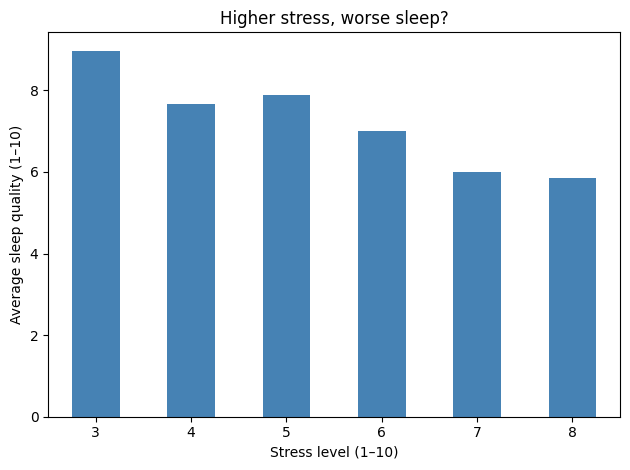

In [5]:
stress_sleep.plot(kind="bar", color="steelblue")
plt.xlabel("Stress level (1–10)")
plt.ylabel("Average sleep quality (1–10)")
plt.title("Higher stress, worse sleep?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
r = df["Stress Level"].corr(df["Quality of Sleep"])
print(f"Correlation between stress and sleep quality: {r:.2f}")

Correlation between stress and sleep quality: -0.90


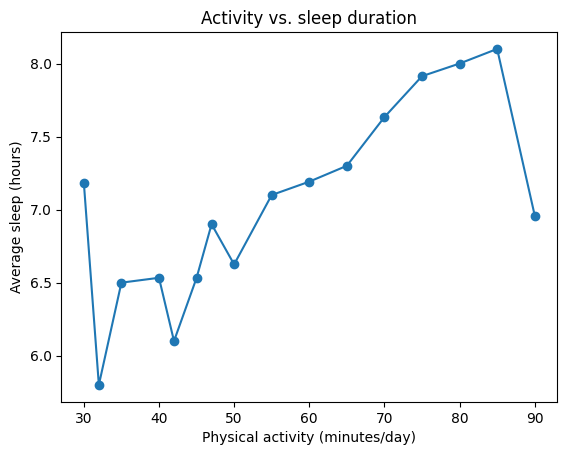

In [7]:
# Does activity relate to sleep duration?
df.groupby("Physical Activity Level")["Sleep Duration"].mean().plot(kind="line", marker="o")
plt.xlabel("Physical activity (minutes/day)")
plt.ylabel("Average sleep (hours)")
plt.title("Activity vs. sleep duration")
plt.show()

In [8]:
r = df["Physical Activity Level"].corr(df["Sleep Duration"])
print(f"Correlation between physical activity and sleep duration: {r:.2f}")

Correlation between physical activity and sleep duration: 0.21


prediction: lower resting HR indicates higher parasympathetic tone, resulting in better sleep quality.

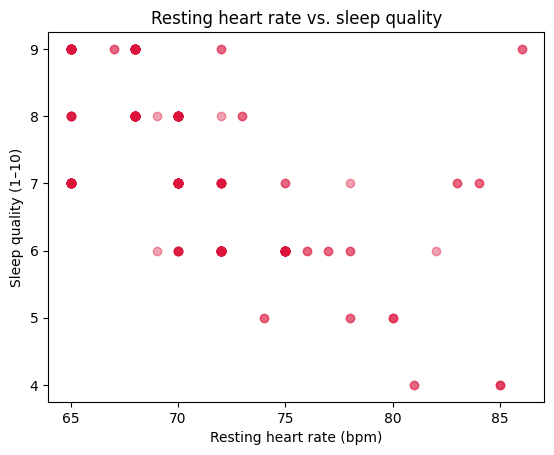

Correlation: -0.66


In [9]:
# Scatter plot: each dot is one person
plt.scatter(df["Heart Rate"], df["Quality of Sleep"], alpha=0.4, color="crimson")
plt.xlabel("Resting heart rate (bpm)")
plt.ylabel("Sleep quality (1–10)")
plt.title("Resting heart rate vs. sleep quality")
plt.show()

# Put a number on it
r = df["Heart Rate"].corr(df["Quality of Sleep"])
print(f"Correlation: {r:.2f}")

In [10]:
df[["Stress Level", "Heart Rate", "Quality of Sleep"]].corr().round(2)

,Stress Level,Heart Rate,Quality of Sleep
Stress Level,1.00,0.67,-0.90
Heart Rate,0.67,1.00,-0.66
Quality of Sleep,-0.90,-0.66,1.00
